# Ablations of AlphaFold3

In this notebook, we perform ablations of AlphaFold3 input channels, to determine the most significant contributors to antigen specicifity prediction.

In [1]:
import collections
import itertools

import IPython.display as ipy_display
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pingouin as pg
import seaborn as sns
from matplotlib.axes import Axes
from matplotlib.ticker import PercentFormatter
from scipy import stats
from sklearn.metrics import auc, precision_recall_curve, roc_auc_score

In [2]:
SIGNIFICANCE_LEVEL = 0.05

In [3]:
ABLATIONS = 'no_unpaired_msas', 'no_paired_msas', 'no_templates'

possible_ablations = [
    combos for combo_size in range(1, len(ABLATIONS) + 1) for combos in itertools.combinations(ABLATIONS, combo_size)
]

## Antigen Specificity

In [4]:
def calculate_performance(pae_scores: pd.Series, labels: pd.Series) -> pd.Series:
    roc_auc = 1 - roc_auc_score(labels, pae_scores)
    roc_auc01 = 1 - roc_auc_score(labels, pae_scores, max_fpr=0.1)

    precision, recall, _ = precision_recall_curve(labels, pae_scores)
    pr_auc = 1 - auc(recall, precision)

    return pd.Series({'roc_auc': roc_auc, 'roc_auc_01': roc_auc01, 'pr_auc': pr_auc})


def format_metric_name(metric_name: str) -> str:
    return metric_name.upper().replace('_01', ' 0.1').replace('_', '-')

In [5]:
def sort_ablations(df: pd.DataFrame) -> pd.DataFrame:
    return df.sort_index(
        key=lambda idx: idx.map(
            lambda name: (
                next(i for i, entry in enumerate(possible_ablations) if name == entry)
                if isinstance(name, tuple)
                else -1
            )
        )
    )

In [6]:
sequences_1500 = pd.read_csv('../data/interim/sequences_sample_1500.csv', index_col='index')
sequences_1500['fold'] = sequences_1500['fold'].astype(str)

In [7]:
af3_confidence_scores = pd.read_csv('../data/processed/confidence_scores_af3_af3_tcrmodel2_1500.csv')

af3_confidence_scores['top_rank'] = False
af3_confidence_scores.loc[af3_confidence_scores.groupby('name')['ranking_score'].idxmax(), 'top_rank'] = True

af3_confidence_scores['ablations'] = ''

ablation_confidence_scores = []
for ablations in possible_ablations:
    ablations_name = '_'.join(ablations)

    confidence_scores = pd.read_csv(f'../data/interim/confidence_scores_af3_af3_tcrmodel2_{ablations_name}_1500.csv')
    confidence_scores['top_rank'] = False
    confidence_scores.loc[confidence_scores.groupby('name')['ranking_score'].idxmax(), 'top_rank'] = True

    confidence_scores['ablations'] = [ablations for _ in range(len(confidence_scores))]

    ablation_confidence_scores.append(confidence_scores)

confidence_scores = pd.concat([af3_confidence_scores, *ablation_confidence_scores]).reset_index(drop=True)

In [8]:
confidence_scores = confidence_scores.merge(sequences_1500, how='left', left_on='name', right_index=True)

### Overall

In [9]:
metric_scores = confidence_scores.groupby('ablations', dropna=False).apply(
    lambda group: calculate_performance(group['cdr_pmhc_pae_score'], group['label']), include_groups=False
)
metric_scores = sort_ablations(metric_scores)

metric_scores_top_rank = (
    confidence_scores.query('top_rank')
    .groupby('ablations', dropna=False)
    .apply(lambda group: calculate_performance(group['cdr_pmhc_pae_score'], group['label']), include_groups=False)
)

metric_scores_top_rank = sort_ablations(metric_scores_top_rank)

print('All')
ipy_display.display(metric_scores)

print()

print('Top Ranked')
ipy_display.display(metric_scores_top_rank)

All


,roc_auc,roc_auc_01,pr_auc
ablations,,,
,0.600320,0.502683,0.551116
"(no_unpaired_msas,)",0.588385,0.505176,0.550498
"(no_paired_msas,)",0.609911,0.504399,0.558316
"(no_templates,)",0.611813,0.506368,0.563316
"(no_unpaired_msas, no_paired_msas)",0.534675,0.505075,0.527168
"(no_unpaired_msas, no_templates)",0.607471,0.508243,0.562761
"(no_paired_msas, no_templates)",0.614985,0.505059,0.564242
"(no_unpaired_msas, no_paired_msas, no_templates)",0.469072,0.496747,0.480077



Top Ranked


,roc_auc,roc_auc_01,pr_auc
ablations,,,
,0.601319,0.504065,0.551730
"(no_unpaired_msas,)",0.587936,0.506124,0.550978
"(no_paired_msas,)",0.613895,0.505806,0.558501
"(no_templates,)",0.611984,0.505301,0.561842
"(no_unpaired_msas, no_paired_msas)",0.540357,0.499640,0.523986
"(no_unpaired_msas, no_templates)",0.607488,0.508959,0.564596
"(no_paired_msas, no_templates)",0.615680,0.505787,0.563064
"(no_unpaired_msas, no_paired_msas, no_templates)",0.475170,0.499995,0.489015


### Bootstrap

In [10]:
NUM_SAMPLES = 25
SAMPLE_SIZE = 500

names = confidence_scores['name'].unique()
rng = np.random.default_rng(123)

samples_metric_scores = []
samples_metric_scores_top_rank = []
for sample_num in range(1, NUM_SAMPLES + 1):
    sample_names = rng.choice(names, SAMPLE_SIZE)

    sample = confidence_scores[confidence_scores['name'].isin(sample_names)]

    sample_metric_scores = (
        sample.groupby('ablations', dropna=False)
        .apply(lambda group: calculate_performance(group['cdr_pmhc_pae_score'], group['label']), include_groups=False)
        .reset_index()
    )
    sample_metric_scores['sample_num'] = sample_num

    samples_metric_scores.append(sample_metric_scores)

    sample_metric_scores_top_rank = (
        sample.query('top_rank')
        .groupby('ablations', dropna=False)
        .apply(lambda group: calculate_performance(group['cdr_pmhc_pae_score'], group['label']), include_groups=False)
        .reset_index()
    )

    sample_metric_scores_top_rank['sample_num'] = sample_num

    samples_metric_scores_top_rank.append(sample_metric_scores_top_rank)

samples_metric_scores = pd.concat(samples_metric_scores).reset_index(drop=True)
samples_metric_scores_top_rank = pd.concat(samples_metric_scores_top_rank).reset_index(drop=True)

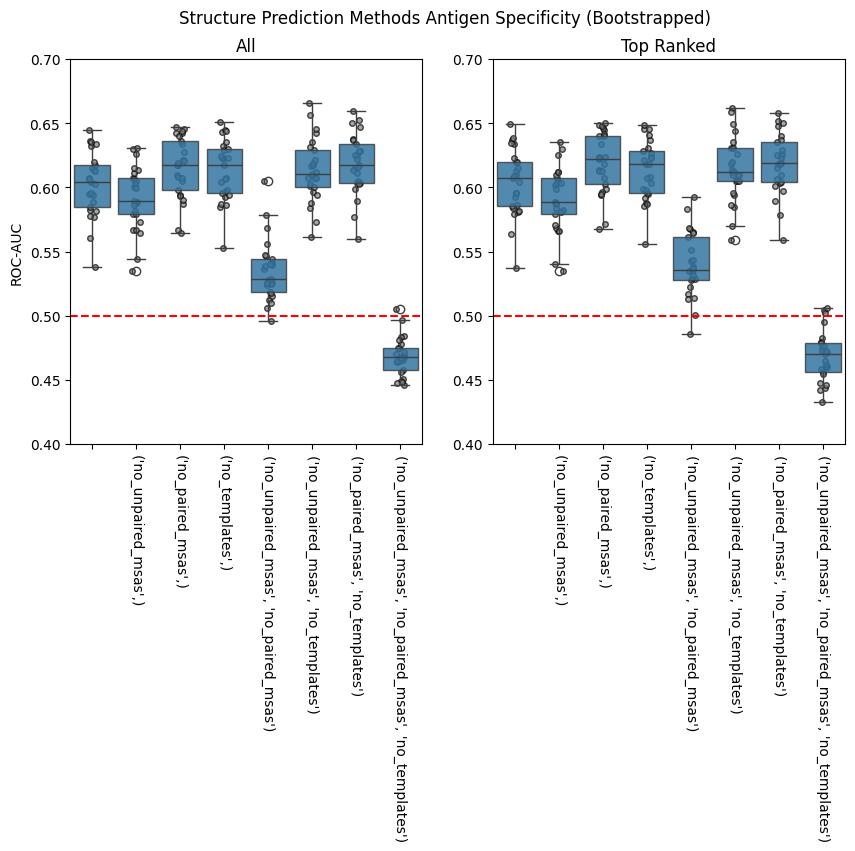

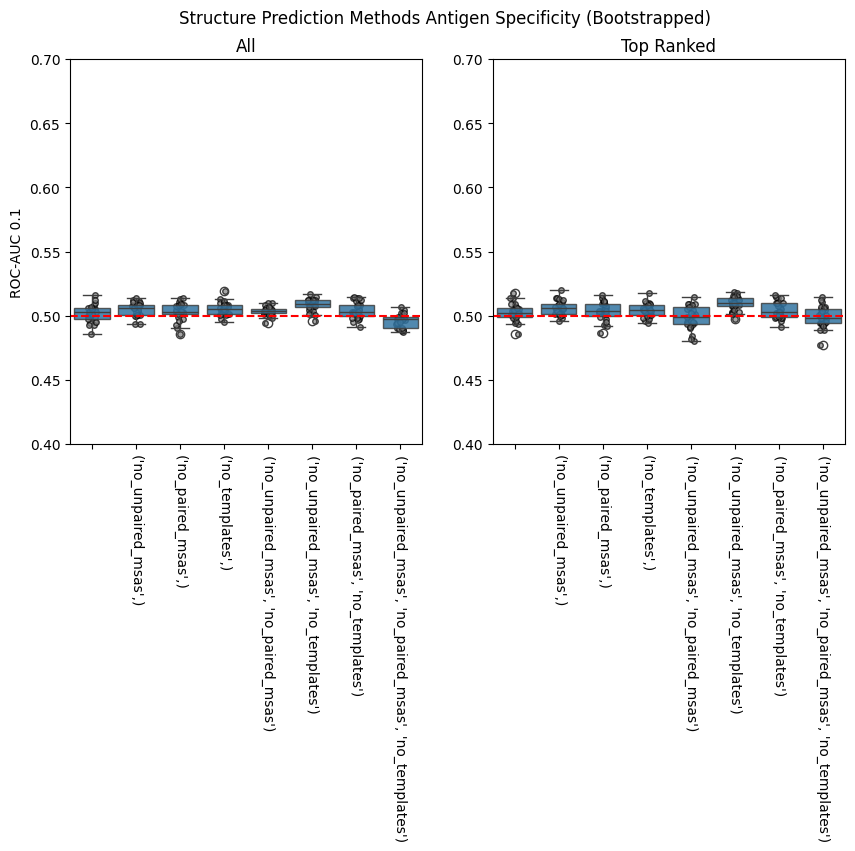

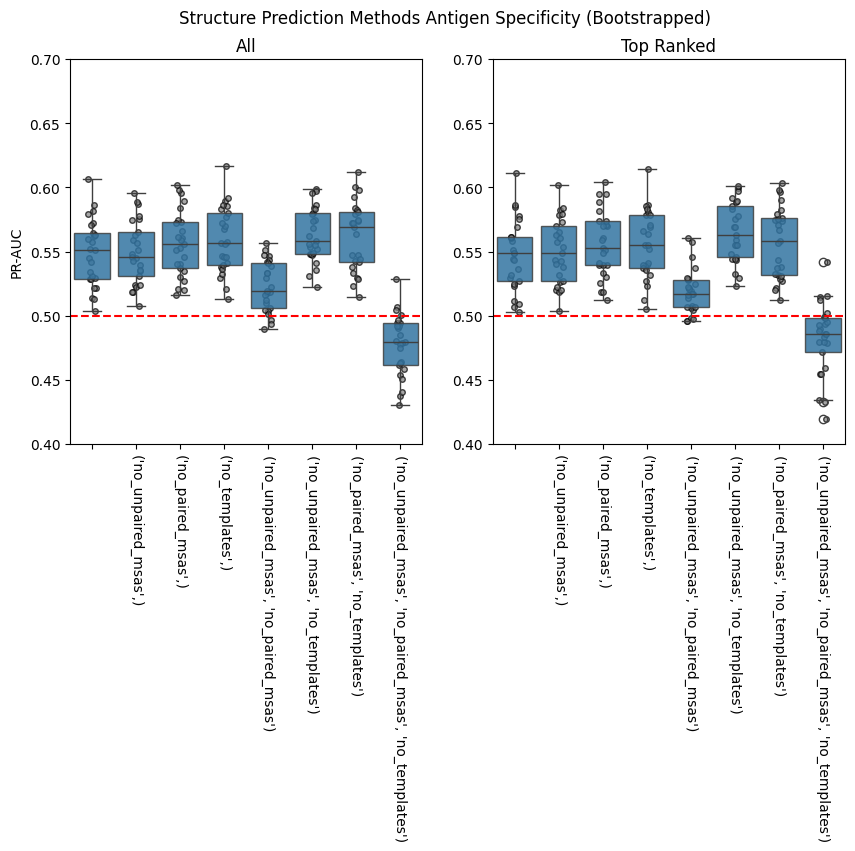

In [11]:
for metric_name in ('roc_auc', 'roc_auc_01', 'pr_auc'):
    fig, axes = plt.subplots(1, 2, figsize=(10, 5))

    fig.suptitle('Structure Prediction Methods Antigen Specificity (Bootstrapped)')

    for i, (ax, title, data) in enumerate(
        zip(axes, ('All', 'Top Ranked'), (samples_metric_scores, samples_metric_scores_top_rank), strict=True)
    ):
        sns.stripplot(
            data,
            x='ablations',
            y=metric_name,
            order=['', *possible_ablations],
            color='grey',
            zorder=1,
            marker='o',
            size=4,
            edgecolor='black',
            linewidth=1,
            alpha=0.70,
            ax=ax,
        )
        sns.boxplot(
            data, x='ablations', y=metric_name, order=['', *possible_ablations], boxprops={'alpha': 0.85}, ax=ax
        )

        ax.axhline(0.5, color='r', linestyle='dashed')

        ax.set_title(title)
        ax.set_xlabel('')

        ax.set_ylim(0.4, 0.7)

        ax.set_xticks(ax.get_xticks())
        ax.set_xticklabels(ax.get_xticklabels(), rotation=270)

        if i == 0:
            ax.set_ylabel(format_metric_name(metric_name))

        else:
            ax.set_ylabel('')

    plt.show()

In [12]:
norm_val = stats.norm.ppf(1 - SIGNIFICANCE_LEVEL / 2)

print('All')
scores_agg = metric_scores.join(
    samples_metric_scores.set_index('sample_num').groupby('ablations').agg('std'), rsuffix='_std'
)
for metric in 'roc_auc', 'roc_auc_01', 'pr_auc':
    scores_agg[f'{metric}_ci'] = scores_agg.apply(
        lambda row, metric=metric, norm_val=norm_val: (
            row[metric] - norm_val * row[f'{metric}_std'],
            row[metric] + norm_val * row[f'{metric}_std'],
        ),
        axis=1,
    )

ipy_display.display(scores_agg)

print()

print('Top Ranked')
scores_agg_top_rank = metric_scores_top_rank.join(
    samples_metric_scores_top_rank.set_index('sample_num').groupby('ablations').agg('std'), rsuffix='_std'
)
for metric in 'roc_auc', 'roc_auc_01', 'pr_auc':
    scores_agg_top_rank[f'{metric}_ci'] = scores_agg_top_rank.apply(
        lambda row, metric=metric, norm_val=norm_val: (
            row[metric] - norm_val * row[f'{metric}_std'],
            row[metric] + norm_val * row[f'{metric}_std'],
        ),
        axis=1,
    )

ipy_display.display(scores_agg_top_rank)

All


,roc_auc,roc_auc_01,pr_auc,roc_auc_std,roc_auc_01_std,pr_auc_std,roc_auc_ci,roc_auc_01_ci,pr_auc_ci
ablations,,,,,,,,,
,0.600320,0.502683,0.551116,0.025469,0.006819,0.026198,"(0.5504016919044719, 0.6502373125399725)","(0.4893183897778612, 0.5160482534969927)","(0.4997693573792726, 0.6024633599508432)"
"(no_unpaired_msas,)",0.588385,0.505176,0.550498,0.024822,0.005337,0.024493,"(0.53973369488895, 0.6370355851110501)","(0.4947153158846625, 0.5156365905480859)","(0.5024927942842009, 0.59850226953571)"
"(no_paired_msas,)",0.609911,0.504399,0.558316,0.023862,0.006783,0.025382,"(0.5631419893845456, 0.6566807306154544)","(0.4911054043894334, 0.5176925371310344)","(0.5085675882678521, 0.6080634925958507)"
"(no_templates,)",0.611813,0.506368,0.563316,0.023864,0.005210,0.025724,"(0.5650398230184308, 0.6585865592037914)","(0.4961575574448362, 0.5165791910931755)","(0.5128974200307246, 0.6137345628749358)"
"(no_unpaired_msas, no_paired_msas)",0.534675,0.505075,0.527168,0.024022,0.003391,0.019513,"(0.4875930874062356, 0.5817563170382088)","(0.49842854510381973, 0.5117212560657709)","(0.4889219451485757, 0.5654131428884627)"
"(no_unpaired_msas, no_templates)",0.607471,0.508243,0.562761,0.024727,0.004786,0.021333,"(0.5590071250041497, 0.6559353816625169)","(0.498862338103797, 0.5176242116038053)","(0.5209491804435964, 0.6045737548247034)"
"(no_paired_msas, no_templates)",0.614985,0.505059,0.564242,0.023564,0.006570,0.026723,"(0.5688003260448832, 0.6611699495106723)","(0.4921823445256979, 0.51793526950939)","(0.5118657251759033, 0.6166182413061736)"
"(no_unpaired_msas, no_paired_msas, no_templates)",0.469072,0.496747,0.480077,0.014880,0.005310,0.023997,"(0.4399072552276217, 0.4982369581057116)","(0.48634092520412736, 0.5071539052052293)","(0.4330434007412127, 0.5271096237723205)"



Top Ranked


,roc_auc,roc_auc_01,pr_auc,roc_auc_std,roc_auc_01_std,pr_auc_std,roc_auc_ci,roc_auc_01_ci,pr_auc_ci
ablations,,,,,,,,,
,0.601319,0.504065,0.551730,0.026022,0.006927,0.027821,"(0.5503160192449007, 0.6523222029773216)","(0.4904897468434111, 0.5176412473086358)","(0.4972022632270076, 0.6062581358004311)"
"(no_unpaired_msas,)",0.587936,0.506124,0.550978,0.025156,0.005733,0.025362,"(0.5386310544327039, 0.6372409455672962)","(0.4948876790342855, 0.5173602741820886)","(0.5012681778716719, 0.6006870978990737)"
"(no_paired_msas,)",0.613895,0.505806,0.558501,0.023523,0.007325,0.026092,"(0.5677911752457367, 0.6599990469764854)","(0.4914485667541575, 0.5201631291522752)","(0.5073620838806091, 0.6096405118709157)"
"(no_templates,)",0.611984,0.505301,0.561842,0.023040,0.005302,0.026567,"(0.5668259313319859, 0.6571420686680141)","(0.49490905726361156, 0.5156921123270316)","(0.5097716138532717, 0.6139122346600103)"
"(no_unpaired_msas, no_paired_msas)",0.540357,0.499640,0.523986,0.025185,0.009124,0.017562,"(0.4909960473361785, 0.5897186193304882)","(0.48175629128381947, 0.5175232408799232)","(0.48956541202005843, 0.5584064049770608)"
"(no_unpaired_msas, no_templates)",0.607488,0.508959,0.564596,0.025199,0.005369,0.023088,"(0.5580982030865915, 0.6568777969134085)","(0.49843662397063343, 0.5194815046843374)","(0.5193451792592391, 0.6098470305323699)"
"(no_paired_msas, no_templates)",0.615680,0.505787,0.563064,0.023518,0.006423,0.027631,"(0.569584714666911, 0.661775285333089)","(0.49319876200311724, 0.5183755070027305)","(0.5089082304031428, 0.6172191520012008)"
"(no_unpaired_msas, no_paired_msas, no_templates)",0.475170,0.499995,0.489015,0.019581,0.008375,0.028128,"(0.43679109525339954, 0.5135484603021558)","(0.4835809893179673, 0.5164096539568864)","(0.43388437327791807, 0.5441452517336975)"


In [13]:
def calculate_differences(sample_groups: pd.DataFrame) -> pd.DataFrame:
    groups = list(sample_groups.groupby('ablations'))

    groups = sorted(
        groups,
        key=lambda item: (
            next(i for i, entry in enumerate(possible_ablations) if item[0] == entry)
            if isinstance(item[0], tuple)
            else -1
        ),
    )

    differences = {
        'group_name_i': [],
        'group_name_j': [],
        'difference_roc_auc': [],
        'difference_roc_auc_01': [],
        'difference_pr_auc': [],
    }

    for i, (group_name_i, group_i) in enumerate(groups[:-1]):
        for group_name_j, group_j in groups[i + 1 :]:
            for metric in 'roc_auc', 'roc_auc_01', 'pr_auc':
                difference = group_i[metric].iloc[0] - group_j[metric].iloc[0]
                differences[f'difference_{metric}'].append(difference)

            differences['group_name_i'].append(group_name_i)
            differences['group_name_j'].append(group_name_j)

    return pd.DataFrame(differences)

In [14]:
norm_val = stats.norm.ppf(1 - SIGNIFICANCE_LEVEL / 2)

print('All')

metric_scores_differences = calculate_differences(metric_scores)
samples_metric_scores_differences = (
    samples_metric_scores.groupby('sample_num')
    .apply(calculate_differences, include_groups=False)
    .groupby(['group_name_i', 'group_name_j'])
    .agg(['std'])
)
samples_metric_scores_differences.columns = ['_'.join(column) for column in samples_metric_scores_differences.columns]
samples_metric_scores_differences = samples_metric_scores_differences.reset_index()

metric_scores_differences = metric_scores_differences.merge(samples_metric_scores_differences)

for metric in 'roc_auc', 'roc_auc_01', 'pr_auc':
    metric_scores_differences[f'{metric}_ci'] = metric_scores_differences.apply(
        lambda row, metric=metric, norm_val=norm_val: (
            row[f'difference_{metric}'] - norm_val * row[f'difference_{metric}_std'],
            row[f'difference_{metric}'] + norm_val * row[f'difference_{metric}_std'],
        ),
        axis=1,
    )

ipy_display.display(metric_scores_differences)

print()

print('Top Rank')

metric_scores_differences_top_rank = calculate_differences(metric_scores_top_rank)
samples_metric_scores_differences_top_rank = (
    samples_metric_scores_top_rank.groupby('sample_num')
    .apply(calculate_differences, include_groups=False)
    .groupby(['group_name_i', 'group_name_j'])
    .agg(['std'])
)
samples_metric_scores_differences_top_rank.columns = [
    '_'.join(column) for column in samples_metric_scores_differences_top_rank.columns
]
samples_metric_scores_differences_top_rank = samples_metric_scores_differences_top_rank.reset_index()

metric_scores_differences_top_rank = metric_scores_differences_top_rank.merge(
    samples_metric_scores_differences_top_rank
)

for metric in 'roc_auc', 'roc_auc_01', 'pr_auc':
    metric_scores_differences_top_rank[f'{metric}_ci'] = metric_scores_differences_top_rank.apply(
        lambda row, metric=metric, norm_val=norm_val: (
            row[f'difference_{metric}'] - norm_val * row[f'difference_{metric}_std'],
            row[f'difference_{metric}'] + norm_val * row[f'difference_{metric}_std'],
        ),
        axis=1,
    )

ipy_display.display(metric_scores_differences_top_rank)

print()

All


,group_name_i,group_name_j,difference_roc_auc,difference_roc_auc_01,difference_pr_auc,difference_roc_auc_std,difference_roc_auc_01_std,difference_pr_auc_std,roc_auc_ci,roc_auc_01_ci,pr_auc_ci
0,,"(no_unpaired_msas,)",0.011935,-0.002493,0.000619,0.010517,0.006029,0.010520,"(-0.008678981006884672, 0.03254870545132903)","(-0.014310151257492913, 0.009324888099598309)","(-0.019999156084804414, 0.02123680959500941)"
1,,"(no_paired_msas,)",-0.009592,-0.001716,-0.007199,0.009308,0.004499,0.009736,"(-0.027834829117128302, 0.008651113561572655)","(-0.010533539521646179, 0.007102241276032234)","(-0.026280703112014414, 0.011882339578427492)"
2,,"(no_templates,)",-0.011494,-0.003685,-0.012200,0.009878,0.004407,0.008138,"(-0.030853266651137023, 0.007865888873359206)","(-0.01232263994156815, 0.004952534678410305)","(-0.028150444121389385, 0.0037511785458448806)"
3,,"(no_unpaired_msas, no_paired_msas)",0.065645,-0.002392,0.023949,0.027021,0.007336,0.018531,"(0.012683936605497118, 0.11860566339450278)","(-0.01676915711702749, 0.011985999222290667)","(-0.012370379332128145, 0.06026800862520565)"
4,,"(no_unpaired_msas, no_templates)",-0.007152,-0.005560,-0.011645,0.015256,0.006511,0.011357,"(-0.03705259114536498, 0.022749088923142768)","(-0.01832198920582451, 0.007202082773075994)","(-0.033904453103605084, 0.010614235165421104)"
5,,"(no_paired_msas, no_templates)",-0.014666,-0.002375,-0.013126,0.011290,0.005758,0.010639,"(-0.036793789245267154, 0.007462518134156042)","(-0.013661596984738051, 0.008910626224504043)","(-0.03397815423368761, 0.007726905081726521)"
6,,"(no_unpaired_msas, no_paired_msas, no_templates)",0.131247,0.005936,0.071040,0.028371,0.008252,0.022149,"(0.0756420076250916, 0.18685278348601947)","(-0.010237319673980689, 0.02210913253947779)","(0.027629541871869667, 0.11445015094471295)"
7,"(no_unpaired_msas,)","(no_paired_msas,)",-0.021527,0.000777,-0.007818,0.010927,0.006461,0.011114,"(-0.04294408883909984, -0.00010935116090015837)","(-0.01188718877640605, 0.01344115368868671)","(-0.029601441614182315, 0.013965424570390399)"
8,"(no_unpaired_msas,)","(no_templates,)",-0.023429,-0.001192,-0.012818,0.012613,0.004618,0.009768,"(-0.04815014091250174, 0.001293038690279573)","(-0.010243234854841398, 0.007858392749578157)","(-0.0319628318147495, 0.006325912729000002)"
9,"(no_unpaired_msas,)","(no_unpaired_msas, no_paired_msas)",0.053710,0.000101,0.023330,0.024145,0.006068,0.017694,"(0.0063861058781881225, 0.10103376967736742)","(-0.011791216761176705, 0.011993322024334487)","(-0.011348958614042469, 0.05800893439691498)"



Top Rank


,group_name_i,group_name_j,difference_roc_auc,difference_roc_auc_01,difference_pr_auc,difference_roc_auc_std,difference_roc_auc_01_std,difference_pr_auc_std,roc_auc_ci,roc_auc_01_ci,pr_auc_ci
0,,"(no_unpaired_msas,)",0.013383,-0.002058,0.000753,0.009457,0.006597,0.009231,"(-0.005153046524390213, 0.03191926874661246)","(-0.014988661317002307, 0.01087170225267501)","(-0.01733939966935262, 0.018844522926045784)"
1,,"(no_paired_msas,)",-0.012576,-0.001740,-0.006771,0.008962,0.004418,0.010438,"(-0.030141373755969623, 0.004989373755969782)","(-0.01039927342599937, 0.006918571671613508)","(-0.027230013143488777, 0.013687816419402702)"
2,,"(no_templates,)",-0.010665,-0.001235,-0.010112,0.010370,0.004732,0.008647,"(-0.030988775804966392, 0.009658998027188722)","(-0.010510043858461118, 0.008039868419864829)","(-0.02705982542112259, 0.006836375935279276)"
3,,"(no_unpaired_msas, no_paired_msas)",0.060962,0.004426,0.027744,0.031100,0.009841,0.023127,"(7.872879426530643e-06, 0.12191568267612904)","(-0.014863042933139278, 0.0237145049214435)","(-0.017584048388425012, 0.07307263041874448)"
4,,"(no_unpaired_msas, no_templates)",-0.006169,-0.004894,-0.012866,0.015361,0.007116,0.011321,"(-0.03627628524432641, 0.023938507466548627)","(-0.018840279646344514, 0.009053145143420614)","(-0.035054964806682215, 0.009323154042512018)"
5,,"(no_paired_msas, no_templates)",-0.014361,-0.001722,-0.011333,0.010787,0.005693,0.012474,"(-0.035502943034061804, 0.006781165256284066)","(-0.012878738775230818, 0.009435463921429903)","(-0.03578274254999223, 0.013115759173087362)"
6,,"(no_unpaired_msas, no_paired_msas, no_templates)",0.126149,0.004070,0.062715,0.033231,0.011606,0.028461,"(0.0610184571362382, 0.19128020953042868)","(-0.01867794193430012, 0.026818292811493234)","(0.006932404881924689, 0.11849836913389845)"
7,"(no_unpaired_msas,)","(no_paired_msas,)",-0.025959,0.000318,-0.007524,0.010884,0.007365,0.010578,"(-0.047291623704794644, -0.00462659851742744)","(-0.014117568167498849, 0.014753825477440283)","(-0.028256307073308548, 0.013208987092529309)"
8,"(no_unpaired_msas,)","(no_templates,)",-0.024048,0.000823,-0.010864,0.012620,0.004955,0.008136,"(-0.04878222350943909, 0.0006862235094391711)","(-0.008887461554673399, 0.010534245180404406)","(-0.02681092493476408, 0.0050823521922276)"
9,"(no_unpaired_msas,)","(no_unpaired_msas, no_paired_msas)",0.047579,0.006484,0.026992,0.027908,0.011696,0.023233,"(-0.0071207916692204165, 0.10227812500255373)","(-0.016440097530659933, 0.02940851858329145)","(-0.018544484958102556, 0.07252794373172887)"


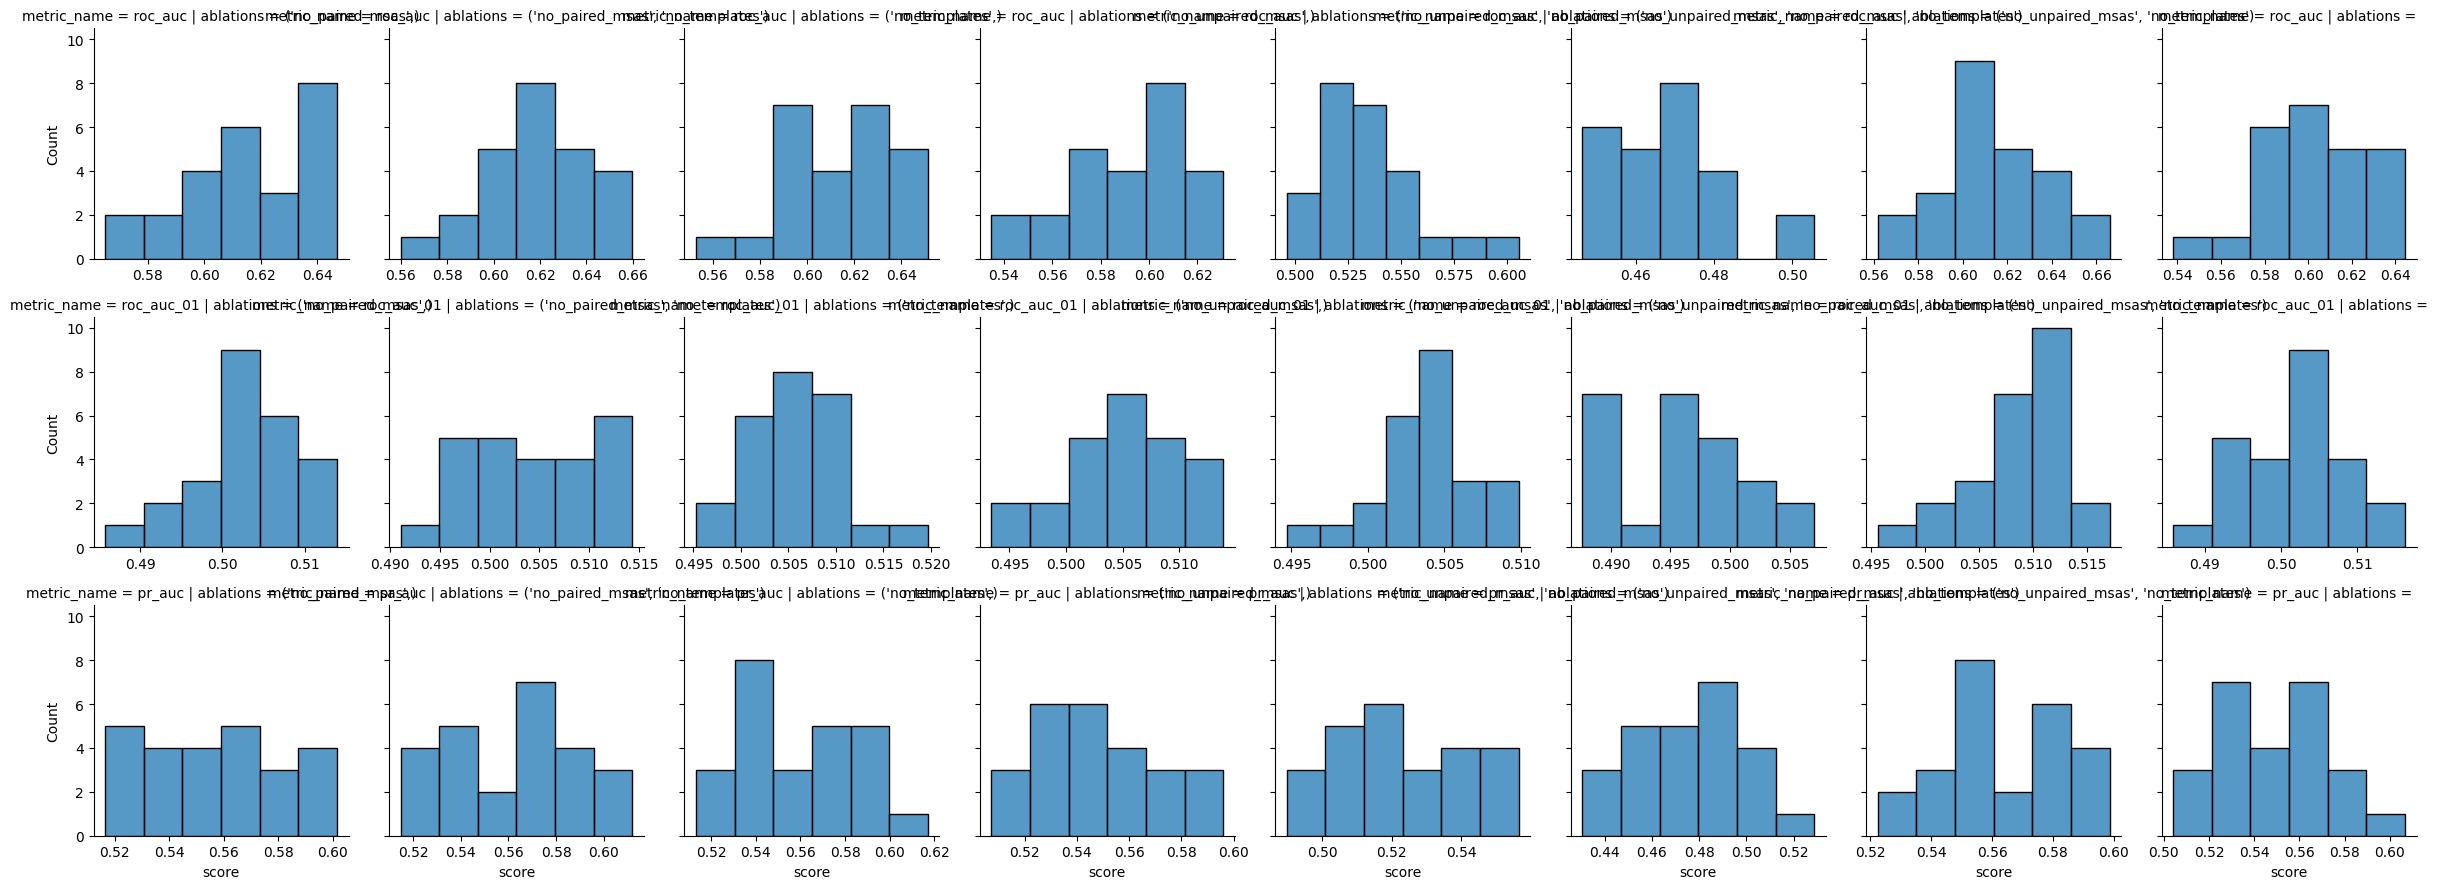

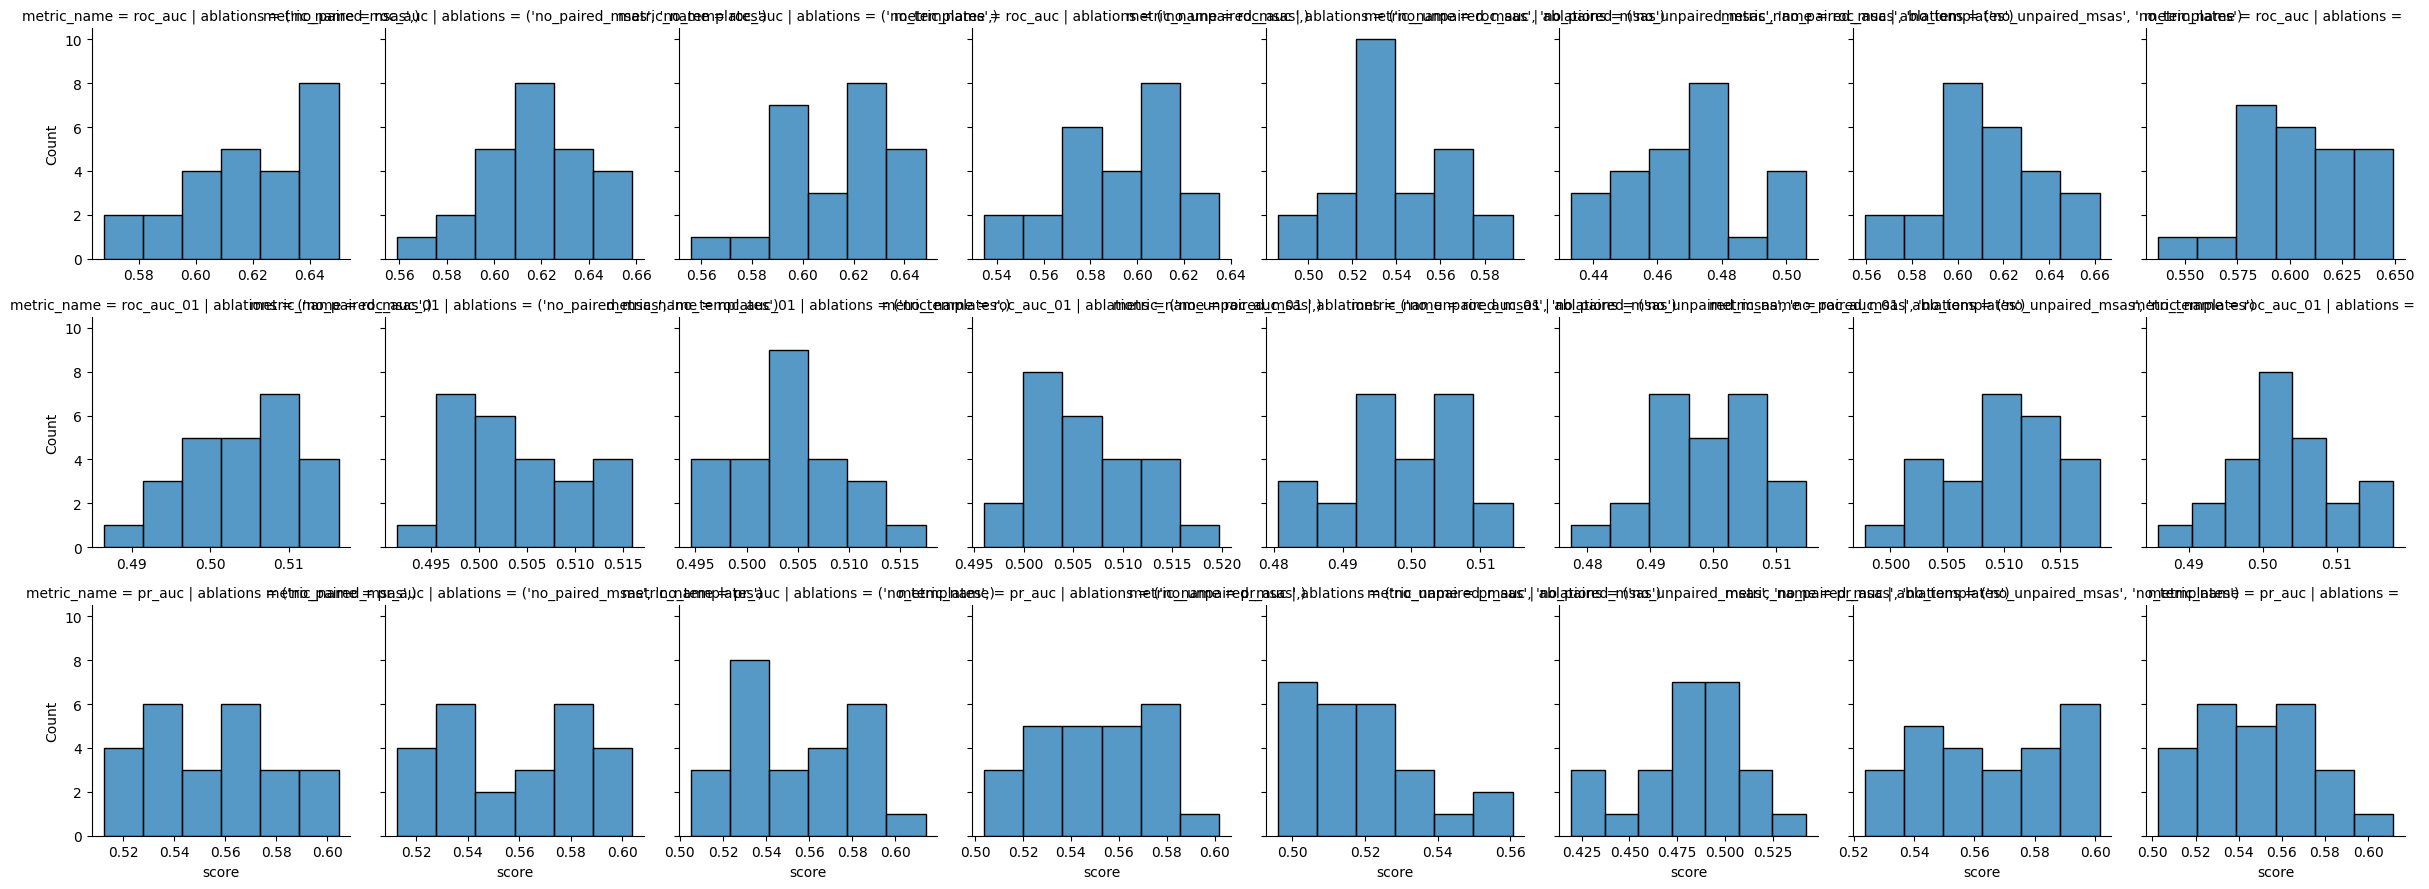

In [15]:
sns.FacetGrid(
    samples_metric_scores.melt(
        id_vars=['ablations', 'sample_num'],
        value_vars=['roc_auc', 'roc_auc_01', 'pr_auc'],
        var_name='metric_name',
        value_name='score',
    ),
    col='ablations',
    row='metric_name',
    sharex=False,
).map(sns.histplot, 'score')

sns.FacetGrid(
    samples_metric_scores_top_rank.melt(
        id_vars=['ablations', 'sample_num'],
        value_vars=['roc_auc', 'roc_auc_01', 'pr_auc'],
        var_name='metric_name',
        value_name='score',
    ),
    col='ablations',
    row='metric_name',
    sharex=False,
).map(sns.histplot, 'score')

plt.show()

In [16]:
def statistics_normal(data: pd.DataFrame, metric_name: str) -> tuple[pd.DataFrame, pd.DataFrame]:
    overall = pg.anova(data, dv=metric_name, between='ablations')

    groups = list(data.groupby('ablations', dropna=False)[metric_name])

    significance_level = 0.05 / len(groups)

    post_hoc = collections.defaultdict(list)
    for (group1_name, group1), (group2_name, group2) in itertools.combinations(groups, 2):
        stat, p_val = stats.ttest_ind(group1, group2, alternative='two-sided')

        post_hoc['group1'].append(group1_name)
        post_hoc['group2'].append(group2_name)
        post_hoc['stat'].append(stat)
        post_hoc['p_val'].append(p_val)
        post_hoc['signficant'].append(p_val < significance_level)

    return overall, pd.DataFrame(post_hoc)

In [17]:
for metric_name in ('roc_auc', 'roc_auc_01', 'pr_auc'):
    print(format_metric_name(metric_name))

    for title, data in zip(('All', 'Top Ranked'), (samples_metric_scores, samples_metric_scores_top_rank), strict=True):
        print(title)
        overall, post_hoc = statistics_normal(data, metric_name)

        ipy_display.display(overall)
        ipy_display.display(post_hoc)
        print()

ROC-AUC
All


,Source,ddof1,ddof2,F,p-unc,np2
0,ablations,7,192,130.788631,1.543409e-69,0.82664


,group1,group2,stat,p_val,signficant
0,"(no_paired_msas, no_templates)","(no_paired_msas,)",0.474729,6.371333e-01,False
1,"(no_paired_msas, no_templates)","(no_templates,)",0.794956,4.305523e-01,False
2,"(no_paired_msas, no_templates)","(no_unpaired_msas, no_paired_msas, no_templates)",26.923429,1.281234e-30,True
3,"(no_paired_msas, no_templates)","(no_unpaired_msas, no_paired_msas)",12.396753,1.423362e-16,True
4,"(no_paired_msas, no_templates)","(no_unpaired_msas, no_templates)",0.778738,4.399562e-01,False
5,"(no_paired_msas, no_templates)","(no_unpaired_msas,)",3.904254,2.947050e-04,True
6,"(no_paired_msas, no_templates)",,2.312462,2.508565e-02,False
7,"(no_paired_msas,)","(no_templates,)",0.318253,7.516733e-01,False
8,"(no_paired_msas,)","(no_unpaired_msas, no_paired_msas, no_templates)",26.115435,5.046971e-30,True
9,"(no_paired_msas,)","(no_unpaired_msas, no_paired_msas)",11.849841,7.358626e-16,True



Top Ranked


,Source,ddof1,ddof2,F,p-unc,np2
0,ablations,7,192,123.592005,1.314015e-67,0.818379


...

,Source,ddof1,ddof2,F,p-unc,np2
0,ablations,7,192,36.076202,7.020156e-32,0.568086


,group1,group2,stat,p_val,signficant
0,"(no_paired_msas, no_templates)","(no_paired_msas,)",0.738985,4.635148e-01,False
1,"(no_paired_msas, no_templates)","(no_templates,)",0.368186,7.143530e-01,False
2,"(no_paired_msas, no_templates)","(no_unpaired_msas, no_paired_msas, no_templates)",11.729428,1.062026e-15,True
3,"(no_paired_msas, no_templates)","(no_unpaired_msas, no_paired_msas)",5.864362,4.037200e-07,True
4,"(no_paired_msas, no_templates)","(no_unpaired_msas, no_templates)",-0.221839,8.253802e-01,False
5,"(no_paired_msas, no_templates)","(no_unpaired_msas,)",1.732452,8.961485e-02,False
6,"(no_paired_msas, no_templates)",,1.734347,8.927509e-02,False
7,"(no_paired_msas,)","(no_templates,)",-0.375753,7.087563e-01,False
8,"(no_paired_msas,)","(no_unpaired_msas, no_paired_msas, no_templates)",11.280879,4.234898e-15,True
9,"(no_paired_msas,)","(no_unpaired_msas, no_paired_msas)",5.210243,3.925386e-06,True



Top Ranked


,Source,ddof1,ddof2,F,p-unc,np2
0,ablations,7,192,28.991888,4.688074e-27,0.513854


,group1,group2,stat,p_val,signficant
0,"(no_paired_msas, no_templates)","(no_paired_msas,)",0.165098,8.695601e-01,False
1,"(no_paired_msas, no_templates)","(no_templates,)",0.298944,7.662730e-01,False
2,"(no_paired_msas, no_templates)","(no_unpaired_msas, no_paired_msas, no_templates)",9.464503,1.487290e-12,True
3,"(no_paired_msas, no_templates)","(no_unpaired_msas, no_paired_msas)",5.790287,5.233961e-07,True
4,"(no_paired_msas, no_templates)","(no_unpaired_msas, no_templates)",-1.115516,2.701832e-01,False
5,"(no_paired_msas, no_templates)","(no_unpaired_msas,)",0.936832,3.535350e-01,False
6,"(no_paired_msas, no_templates)",,1.233953,2.232283e-01,False
7,"(no_paired_msas,)","(no_templates,)",0.139232,8.898496e-01,False
8,"(no_paired_msas,)","(no_unpaired_msas, no_paired_msas, no_templates)",9.563128,1.070811e-12,True
9,"(no_paired_msas,)","(no_unpaired_msas, no_paired_msas)",5.827912,4.587577e-07,True


### By Fold

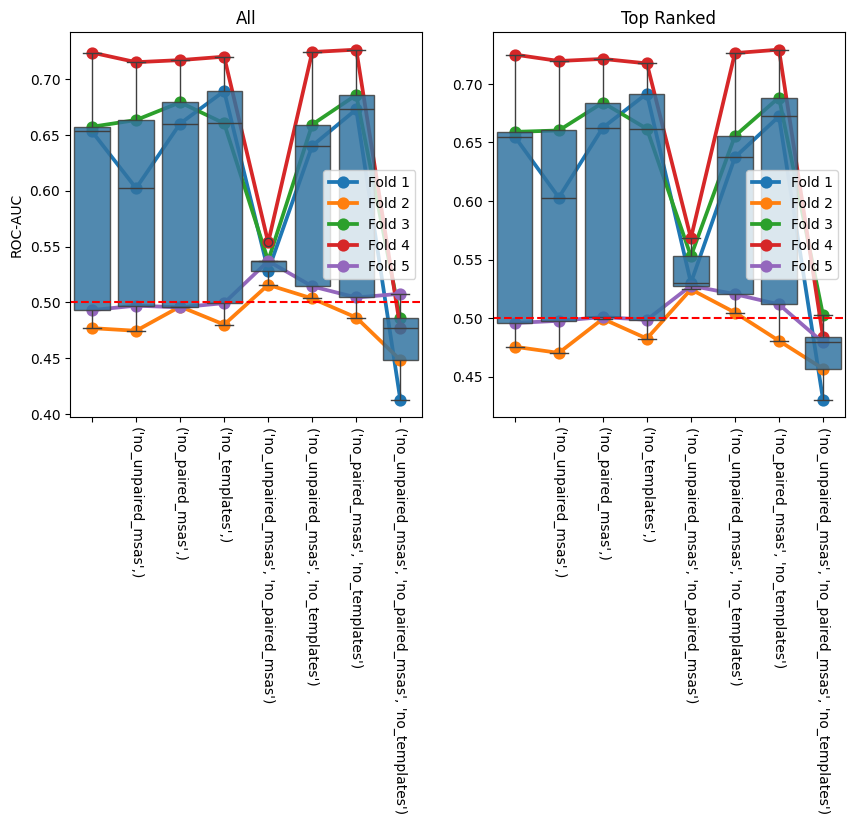

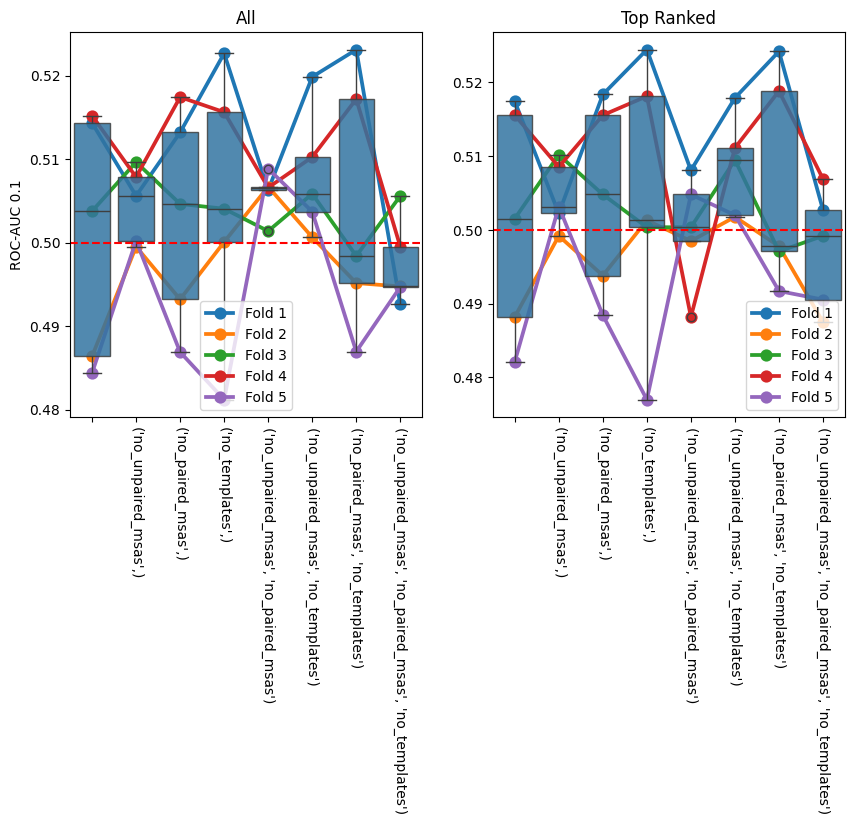

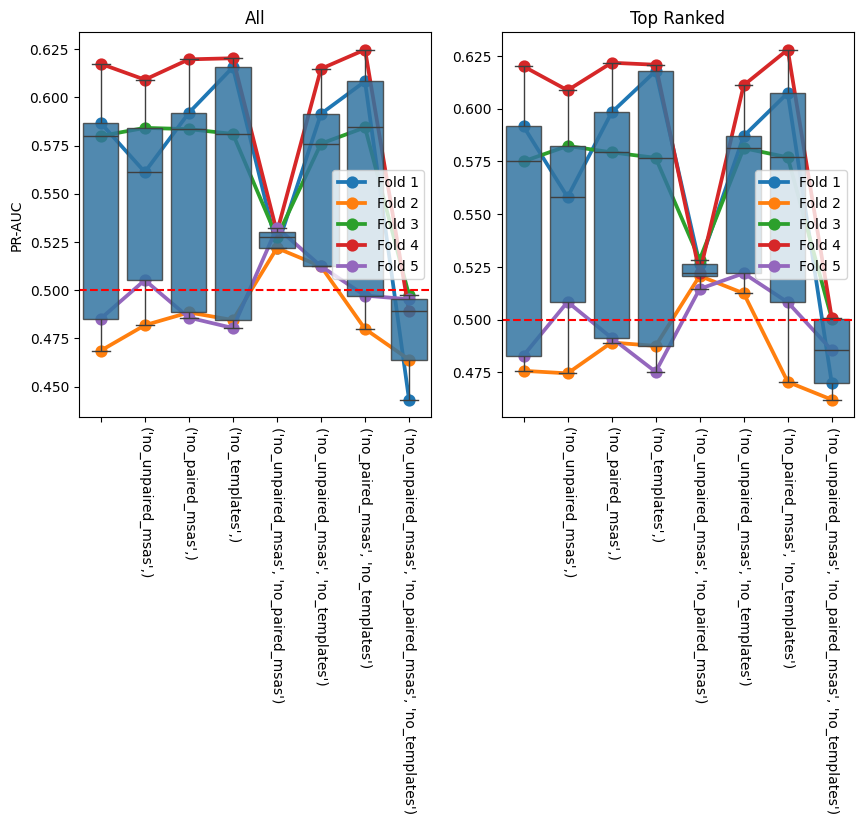

In [18]:
roc_aucs_by_fold = (
    confidence_scores.groupby(['ablations', 'fold'], dropna=False)
    .apply(lambda group: calculate_performance(group['cdr_pmhc_pae_score'], group['label']), include_groups=False)
    .reset_index()
)

roc_aucs_by_fold_top_rank = (
    confidence_scores.query('top_rank')
    .groupby(['ablations', 'fold'], dropna=False)
    .apply(lambda group: calculate_performance(group['cdr_pmhc_pae_score'], group['label']), include_groups=False)
    .reset_index()
)


for metric_name in ('roc_auc', 'roc_auc_01', 'pr_auc'):
    fig, axes = plt.subplots(1, 2, figsize=(10, 5))

    for i, (ax, title, data) in enumerate(
        zip(axes, ('All', 'Top Ranked'), (roc_aucs_by_fold, roc_aucs_by_fold_top_rank), strict=True)
    ):
        sns.pointplot(data, x='ablations', y=metric_name, order=['', *possible_ablations], hue='fold', ax=ax)
        sns.boxplot(
            data, x='ablations', y=metric_name, order=['', *possible_ablations], boxprops={'alpha': 0.85}, ax=ax
        )

        ax.axhline(0.5, color='r', linestyle='dashed')

        ax.set_title(title)
        ax.set_xlabel('')

        ax.set_xticks(ax.get_xticks())
        ax.set_xticklabels(ax.get_xticklabels(), rotation=270)

        handles, labels = ax.get_legend_handles_labels()
        new_labels = [f'Fold {label}' for label in labels]
        ax.legend(handles, new_labels)

        if i == 0:
            ax.set_ylabel(format_metric_name(metric_name))

        else:
            ax.set_ylabel('')

    plt.show()

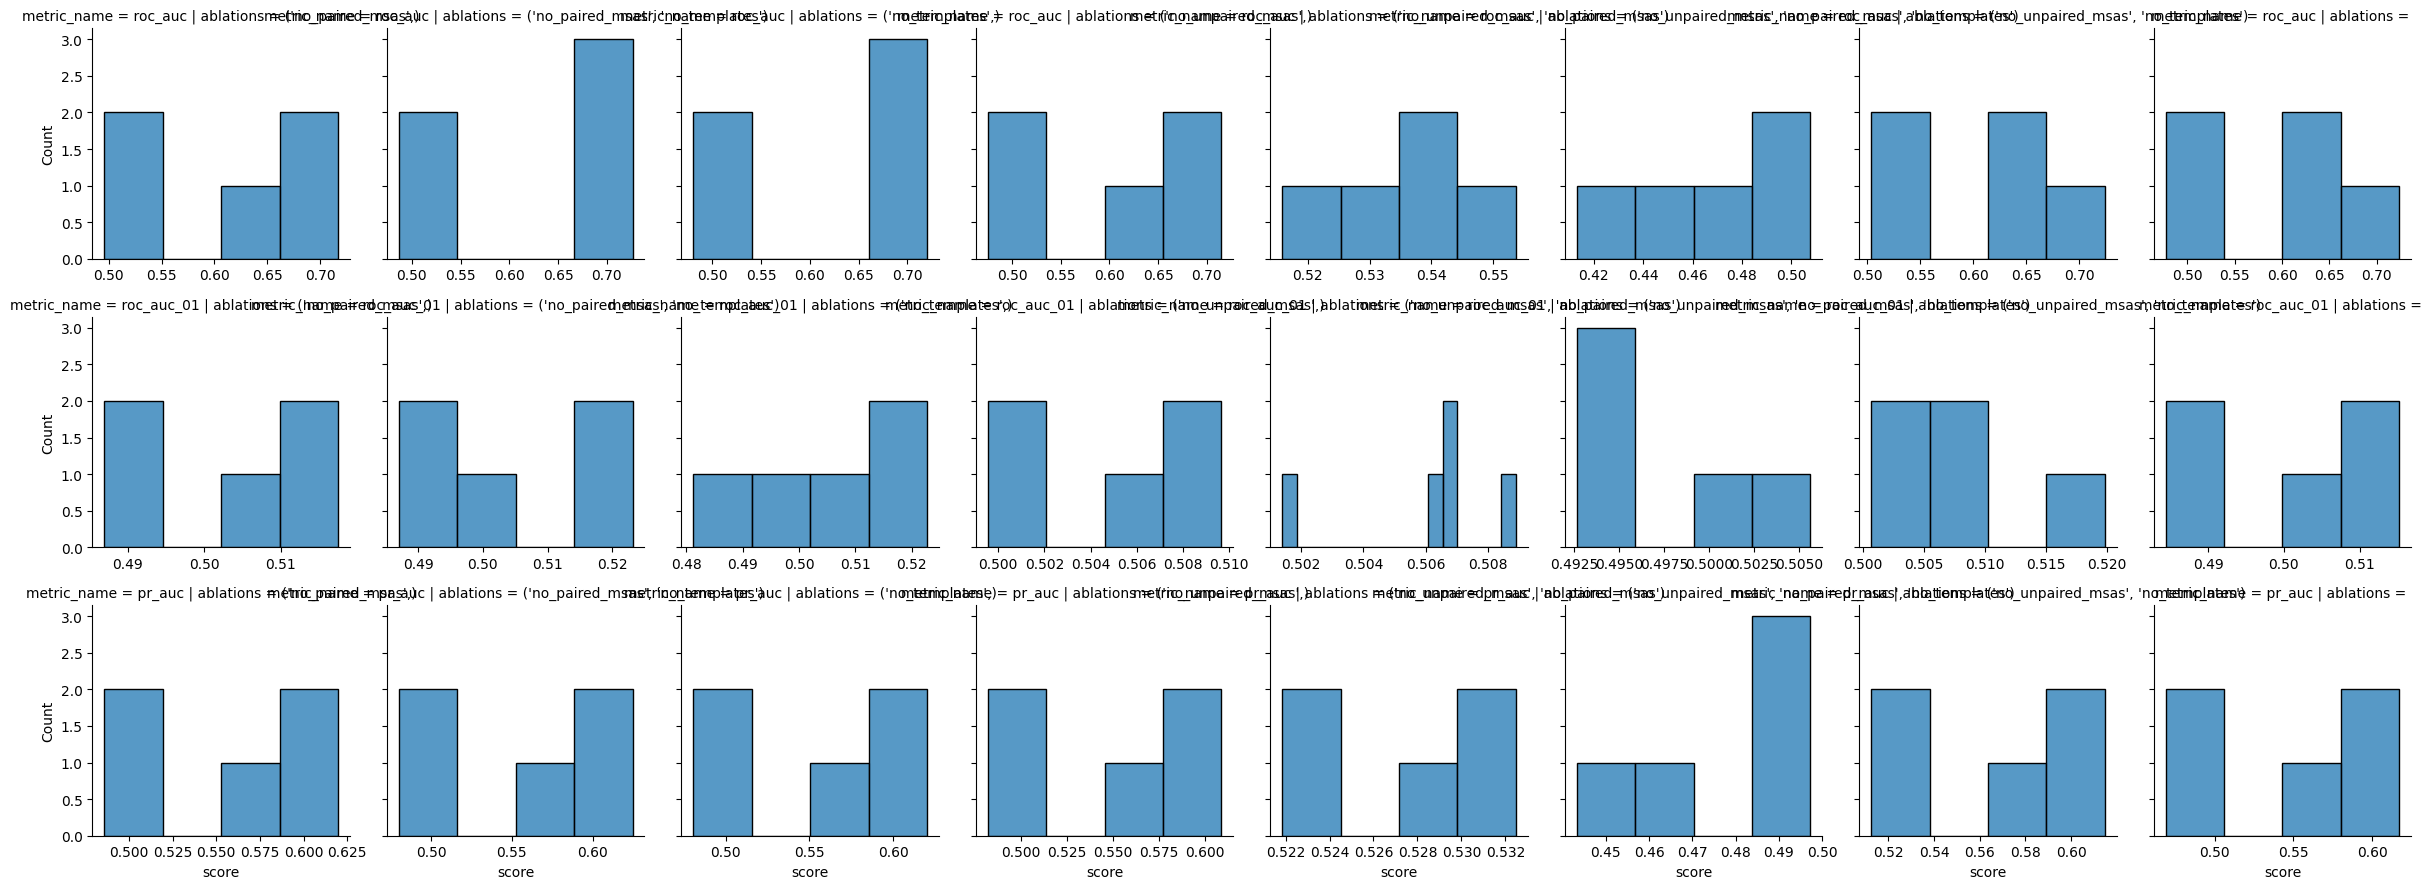

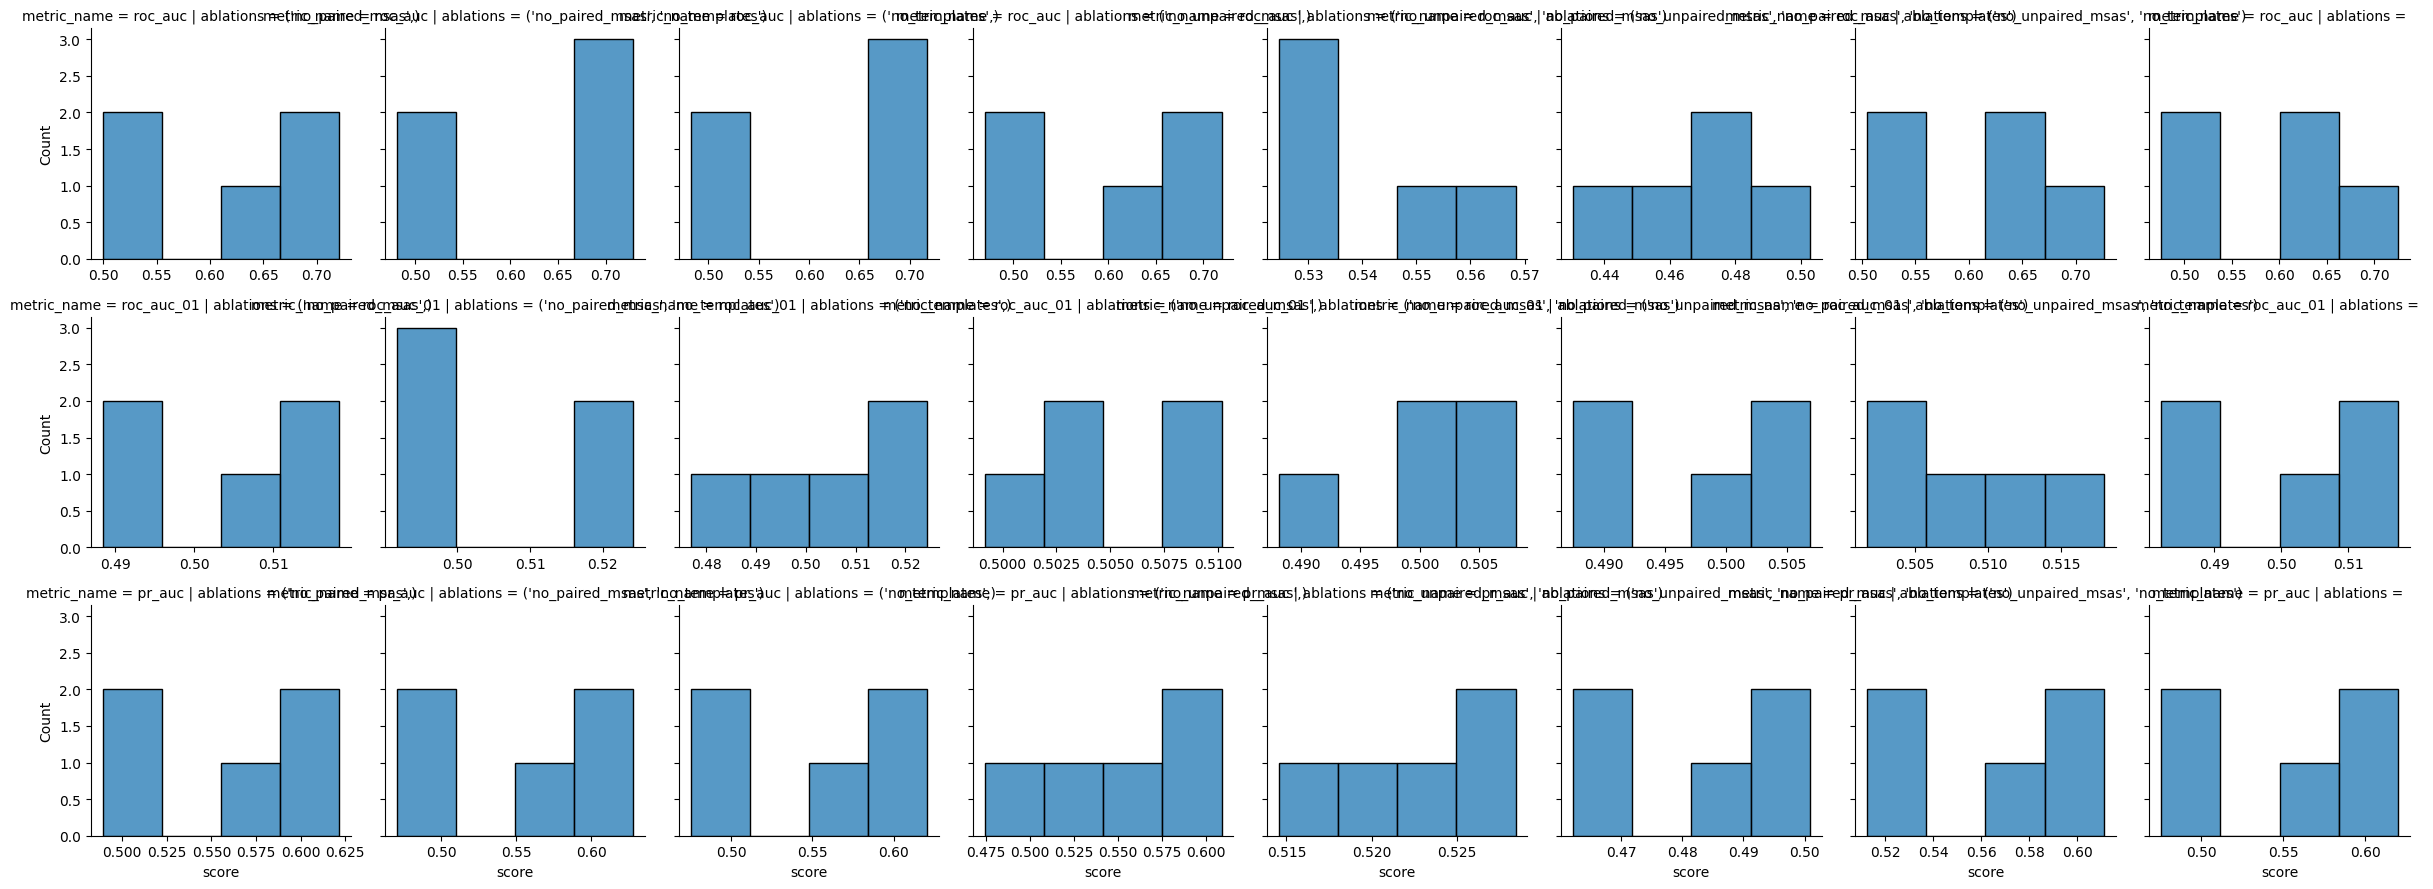

In [19]:
sns.FacetGrid(
    roc_aucs_by_fold.melt(
        id_vars=['ablations', 'fold'],
        value_vars=['roc_auc', 'roc_auc_01', 'pr_auc'],
        var_name='metric_name',
        value_name='score',
    ),
    col='ablations',
    row='metric_name',
    sharex=False,
).map(sns.histplot, 'score')

sns.FacetGrid(
    roc_aucs_by_fold_top_rank.melt(
        id_vars=['ablations', 'fold'],
        value_vars=['roc_auc', 'roc_auc_01', 'pr_auc'],
        var_name='metric_name',
        value_name='score',
    ),
    col='ablations',
    row='metric_name',
    sharex=False,
).map(sns.histplot, 'score')

plt.show()

In [20]:
def statistics_non_parametric(data: pd.DataFrame, metric_name: str) -> tuple[pd.DataFrame, pd.DataFrame]:
    overall = pg.friedman(data, dv=metric_name, within='ablations', subject='fold', method='f')

    groups = list(data.set_index('fold').groupby('ablations')[metric_name])
    groups = [(group_name, group.sort_index()) for group_name, group in groups]

    significance_level = 0.05 / len(groups)

    post_hoc = collections.defaultdict(list)
    for (group1_name, group1), (group2_name, group2) in itertools.combinations(groups, 2):
        stat, p_val = stats.wilcoxon(group1, group2, alternative='greater')

        post_hoc['group1'].append(group1_name)
        post_hoc['group2'].append(group2_name)
        post_hoc['stat'].append(stat)
        post_hoc['p_val'].append(p_val)
        post_hoc['signficant'].append(p_val < significance_level)

    return overall, pd.DataFrame(post_hoc)

In [21]:
for metric_name in ('roc_auc', 'roc_auc_01', 'pr_auc'):
    print(format_metric_name(metric_name))

    for title, data in zip(('All', 'Top Ranked'), (roc_aucs_by_fold, roc_aucs_by_fold_top_rank), strict=True):
        print(title)
        overall, post_hoc = statistics_non_parametric(data, metric_name)

        ipy_display.display(overall)
        ipy_display.display(post_hoc)

        print()

    print()

ROC-AUC
All


,Source,W,ddof1,ddof2,F,p-unc
Friedman,ablations,0.36,6.6,26.4,2.25,0.064774


,group1,group2,stat,p_val,signficant
0,"(no_paired_msas, no_templates)","(no_paired_msas,)",11.0,0.21875,False
1,"(no_paired_msas, no_templates)","(no_templates,)",11.0,0.21875,False
2,"(no_paired_msas, no_templates)","(no_unpaired_msas, no_paired_msas, no_templates)",14.0,0.06250,False
3,"(no_paired_msas, no_templates)","(no_unpaired_msas, no_paired_msas)",12.0,0.15625,False
4,"(no_paired_msas, no_templates)","(no_unpaired_msas, no_templates)",10.0,0.31250,False
5,"(no_paired_msas, no_templates)","(no_unpaired_msas,)",15.0,0.03125,False
6,"(no_paired_msas, no_templates)",,15.0,0.03125,False
7,"(no_paired_msas,)","(no_templates,)",7.0,0.59375,False
8,"(no_paired_msas,)","(no_unpaired_msas, no_paired_msas, no_templates)",14.0,0.06250,False
9,"(no_paired_msas,)","(no_unpaired_msas, no_paired_msas)",12.0,0.15625,False



Top Ranked


,Source,W,ddof1,ddof2,F,p-unc
Friedman,ablations,0.512381,6.6,26.4,4.203125,0.003526


...

,Source,W,ddof1,ddof2,F,p-unc
Friedman,ablations,0.340952,6.6,26.4,2.069364,0.086298


,group1,group2,stat,p_val,signficant
0,"(no_paired_msas, no_templates)","(no_paired_msas,)",12.0,0.15625,False
1,"(no_paired_msas, no_templates)","(no_templates,)",8.0,0.50000,False
2,"(no_paired_msas, no_templates)","(no_unpaired_msas, no_paired_msas, no_templates)",15.0,0.03125,False
3,"(no_paired_msas, no_templates)","(no_unpaired_msas, no_paired_msas)",12.0,0.15625,False
4,"(no_paired_msas, no_templates)","(no_unpaired_msas, no_templates)",7.0,0.59375,False
5,"(no_paired_msas, no_templates)","(no_unpaired_msas,)",10.0,0.31250,False
6,"(no_paired_msas, no_templates)",,15.0,0.03125,False
7,"(no_paired_msas,)","(no_templates,)",9.0,0.40625,False
8,"(no_paired_msas,)","(no_unpaired_msas, no_paired_msas, no_templates)",14.0,0.06250,False
9,"(no_paired_msas,)","(no_unpaired_msas, no_paired_msas)",12.0,0.15625,False



Top Ranked


,Source,W,ddof1,ddof2,F,p-unc
Friedman,ablations,0.358095,6.6,26.4,2.231454,0.066706


,group1,group2,stat,p_val,signficant
0,"(no_paired_msas, no_templates)","(no_paired_msas,)",9.0,0.40625,False
1,"(no_paired_msas, no_templates)","(no_templates,)",8.0,0.50000,False
2,"(no_paired_msas, no_templates)","(no_unpaired_msas, no_paired_msas, no_templates)",15.0,0.03125,False
3,"(no_paired_msas, no_templates)","(no_unpaired_msas, no_paired_msas)",11.0,0.21875,False
4,"(no_paired_msas, no_templates)","(no_unpaired_msas, no_templates)",7.0,0.59375,False
5,"(no_paired_msas, no_templates)","(no_unpaired_msas,)",9.0,0.40625,False
6,"(no_paired_msas, no_templates)",,13.0,0.09375,False
7,"(no_paired_msas,)","(no_templates,)",10.0,0.31250,False
8,"(no_paired_msas,)","(no_unpaired_msas, no_paired_msas, no_templates)",15.0,0.03125,False
9,"(no_paired_msas,)","(no_unpaired_msas, no_paired_msas)",12.0,0.15625,False


## Structure Quality

In [22]:
alphafold3_dockq = pd.read_csv('../data/processed/predicted_af3_af3_tcrmodel2_dockq_benchmark.csv')
alphafold3_benchmark_confidences = pd.read_csv('../data/interim/confidence_scores_af3_af3_tcrmodel2_benchmark.csv')

alphafold3_benchmark_confidences['top_rank'] = False
alphafold3_benchmark_confidences.loc[
    alphafold3_benchmark_confidences.groupby('name')['ranking_score'].idxmax(), 'top_rank'
] = True

alphafold3_dockq = alphafold3_dockq.merge(alphafold3_benchmark_confidences, how='outer', on=['name', 'seed', 'sample'])
alphafold3_dockq = alphafold3_dockq.fillna(0.0)

alphafold3_dockq['ablations'] = ''

In [23]:
ablation_dockqs = []
for ablations in possible_ablations:
    ablations_name = '_'.join(ablations)

    dockq = pd.read_csv(f'../data/processed/predicted_af3_af3_tcrmodel2_{ablations_name}_dockq_benchmark.csv')
    confidences = pd.read_csv(f'../data/interim/confidence_scores_af3_af3_tcrmodel2_{ablations_name}_benchmark.csv')

    confidences['top_rank'] = False
    confidences.loc[confidences.groupby('name')['ranking_score'].idxmax(), 'top_rank'] = True

    dockq = dockq.merge(confidences, how='outer', on=['name', 'seed', 'sample'])
    dockq = dockq.fillna(0.0)

    dockq['ablations'] = [ablations for _ in range(len(dockq))]

    ablation_dockqs.append(dockq)

ablation_dockqs = pd.concat(ablation_dockqs).reset_index(drop=True)

In [24]:
dockq_scores = pd.concat([alphafold3_dockq, ablation_dockqs]).reset_index(drop=True)

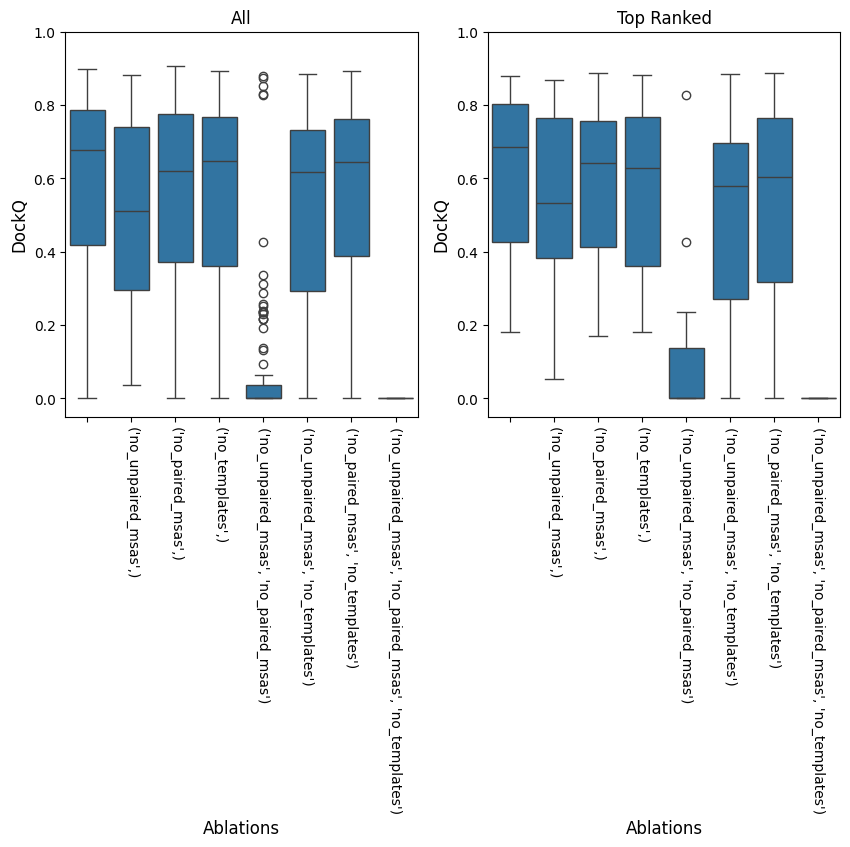

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(10, 5))

for ax, title, data in zip(axes, ('All', 'Top Ranked'), (dockq_scores, dockq_scores.query('top_rank')), strict=True):
    ax.set_title(title)
    sns.boxplot(data, x='ablations', y='DockQ', ax=ax)

    ax.set_xticks(ax.get_xticks())
    ax.set_xticklabels(ax.get_xticklabels(), rotation=270)

    ax.set_xlabel(ax.get_xlabel().title(), fontsize=12)
    ax.set_ylabel(ax.get_ylabel(), fontsize=12)

    ax.set_ylim(-0.05, 1.0)

plt.show()

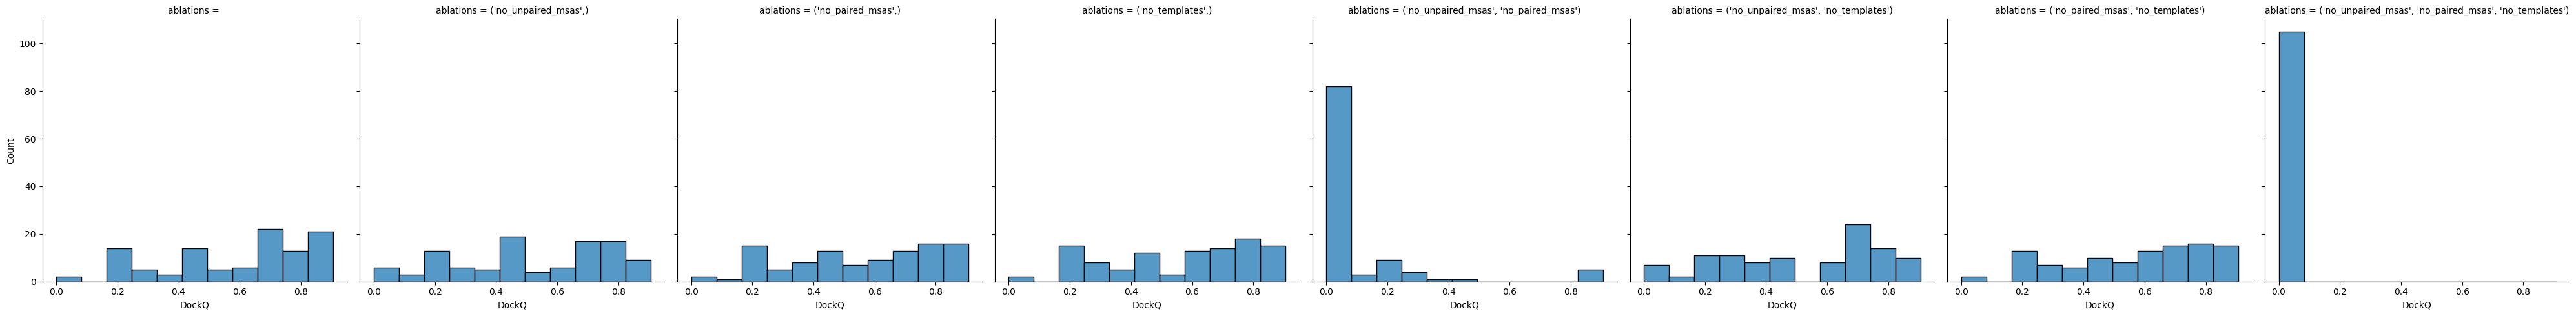

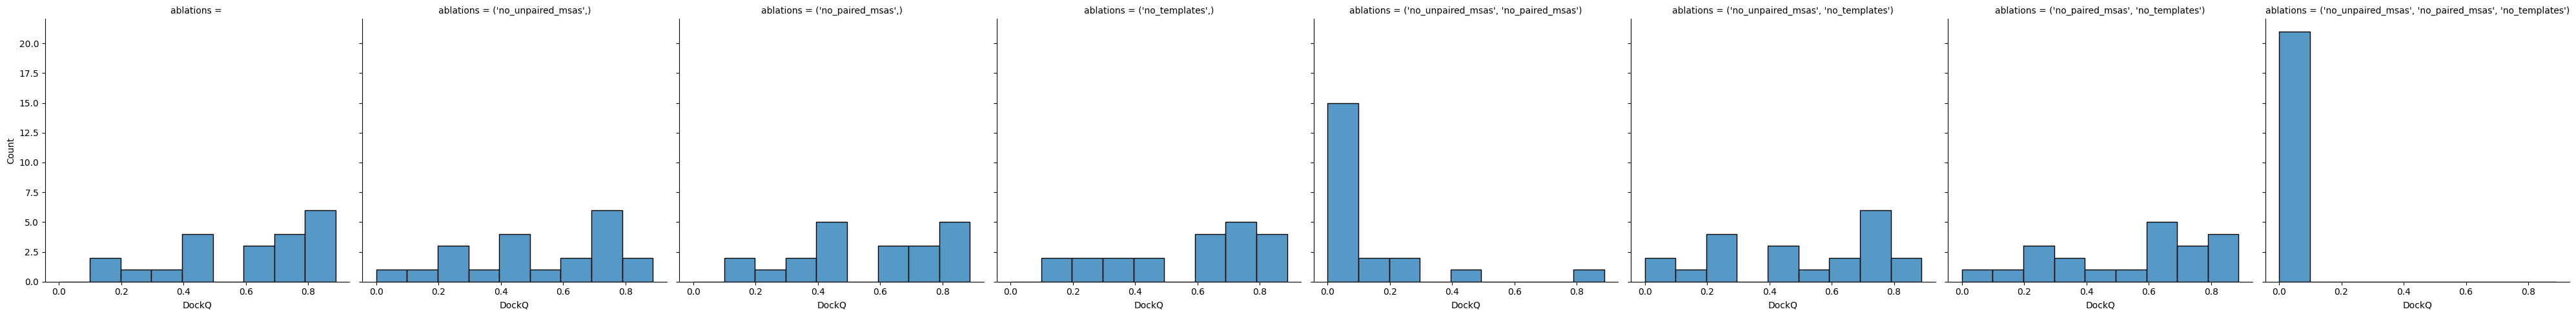

In [26]:
sns.displot(dockq_scores, col='ablations', x='DockQ', kind='hist')
sns.displot(dockq_scores.query('top_rank'), col='ablations', x='DockQ', kind='hist')

plt.show()

In [27]:
for title, data in zip(('All', 'Top Ranked'), (dockq_scores, dockq_scores.query('top_rank')), strict=True):
    print(title)

    ipy_display.display(pg.kruskal(data, dv='DockQ', between='ablations'))

    groups = list(data.groupby('ablations')['DockQ'])

    significance_level = 0.05 / len(groups)

    results = collections.defaultdict(list)
    for (group1_name, group1), (group2_name, group2) in itertools.combinations(groups, 2):
        stat, p_val = stats.ranksums(group1, group2, alternative='two-sided')

        results['group1'].append(group1_name)
        results['group2'].append(group2_name)
        results['stat'].append(stat)
        results['p_val'].append(p_val)
        results['signficant'].append(p_val < significance_level)

    ipy_display.display(pd.DataFrame(results))
    print()

All


,Source,ddof1,H,p-unc
Kruskal,ablations,7,414.319253,2.023723e-85


,group1,group2,stat,p_val,signficant
0,"(no_paired_msas,)","(no_paired_msas, no_templates)",-0.116968,9.068854e-01,False
1,"(no_paired_msas,)","(no_templates,)",0.024983,9.800681e-01,False
2,"(no_paired_msas,)","(no_unpaired_msas,)",1.334344,1.820910e-01,False
3,"(no_paired_msas,)","(no_unpaired_msas, no_paired_msas)",10.738350,6.723509e-27,True
4,"(no_paired_msas,)","(no_unpaired_msas, no_paired_msas, no_templates)",12.400887,2.584478e-35,True
5,"(no_paired_msas,)","(no_unpaired_msas, no_templates)",1.385447,1.659158e-01,False
6,"(no_paired_msas,)",,-0.842624,3.994386e-01,False
7,"(no_paired_msas, no_templates)","(no_templates,)",0.012492,9.900333e-01,False
8,"(no_paired_msas, no_templates)","(no_unpaired_msas,)",1.420651,1.554182e-01,False
9,"(no_paired_msas, no_templates)","(no_unpaired_msas, no_paired_msas)",10.696333,1.058865e-26,True



Top Ranked


,Source,ddof1,H,p-unc
Kruskal,ablations,7,80.641404,1.019214e-14


,group1,group2,stat,p_val,signficant
0,"(no_paired_msas,)","(no_paired_msas, no_templates)",0.213824,8.306845e-01,False
1,"(no_paired_msas,)","(no_templates,)",-0.113201,9.098713e-01,False
2,"(no_paired_msas,)","(no_unpaired_msas,)",0.213824,8.306845e-01,False
3,"(no_paired_msas,)","(no_unpaired_msas, no_paired_msas)",4.691546,2.711489e-06,True
4,"(no_paired_msas,)","(no_unpaired_msas, no_paired_msas, no_templates)",5.546841,2.908775e-08,True
5,"(no_paired_msas,)","(no_unpaired_msas, no_templates)",0.566004,5.713910e-01,False
6,"(no_paired_msas,)",,-0.666627,5.050103e-01,False
7,"(no_paired_msas, no_templates)","(no_templates,)",-0.389914,6.966002e-01,False
8,"(no_paired_msas, no_templates)","(no_unpaired_msas,)",0.213824,8.306845e-01,False
9,"(no_paired_msas, no_templates)","(no_unpaired_msas, no_paired_msas)",4.490300,7.112306e-06,True


In [28]:
CAPRI_ACCEPTABLE_CUTOFF = 0.23
CAPRI_MEDIUM_CUTOFF = 0.49
CAPRI_HIGH_CUTOFF = 0.80


def get_capri_classification(dockq: float) -> str:
    if dockq < CAPRI_ACCEPTABLE_CUTOFF:
        return 'Incorrect'

    if CAPRI_ACCEPTABLE_CUTOFF <= dockq < CAPRI_MEDIUM_CUTOFF:
        return 'Acceptable'

    if CAPRI_MEDIUM_CUTOFF <= dockq < CAPRI_HIGH_CUTOFF:
        return 'Medium'

    return 'High'

In [29]:
dockq_scores['capri_classification'] = dockq_scores['DockQ'].map(get_capri_classification)

In [30]:
def plot_capri_classification(dockq_scores: pd.DataFrame, ax: Axes | None = None) -> Axes:
    order = ['High', 'Medium', 'Acceptable', 'Incorrect']
    colours = {
        'High': '#7f0d0d',
        'Medium': '#ff1a1a',
        'Acceptable': '#ff7f7f',
        'Incorrect': '#e6e6e6',
    }

    capri_classification = dockq_scores.groupby('ablations')['capri_classification'].value_counts(normalize=True) * 100
    capri_classification.name = 'percent'
    capri_classification = capri_classification.reset_index()
    capri_classification = capri_classification.pivot_table(
        index='ablations', columns='capri_classification', values='percent'
    )
    capri_classification = capri_classification.reindex(columns=order, fill_value=0)
    capri_classification = capri_classification.sort_index(
        key=lambda idx: idx.map(
            lambda name: (
                next(i for i, entry in enumerate(possible_ablations) if name == entry)
                if isinstance(name, tuple)
                else -1
            )
        )
    )

    plot_ax = capri_classification.plot(
        kind='bar',
        stacked=True,
        color=[colours[col_name] for col_name in order],
        width=0.8,
        edgecolor='none',
        legend=False,
        ax=ax,
    )

    plot_ax.set_ylim(0, 100)
    plot_ax.yaxis.set_major_formatter(PercentFormatter(xmax=100))
    plot_ax.set_ylabel('Success rate', fontsize=12)
    plot_ax.set_yticks([0, 25, 50, 75, 100])
    plot_ax.set_xlabel('')

    return plot_ax

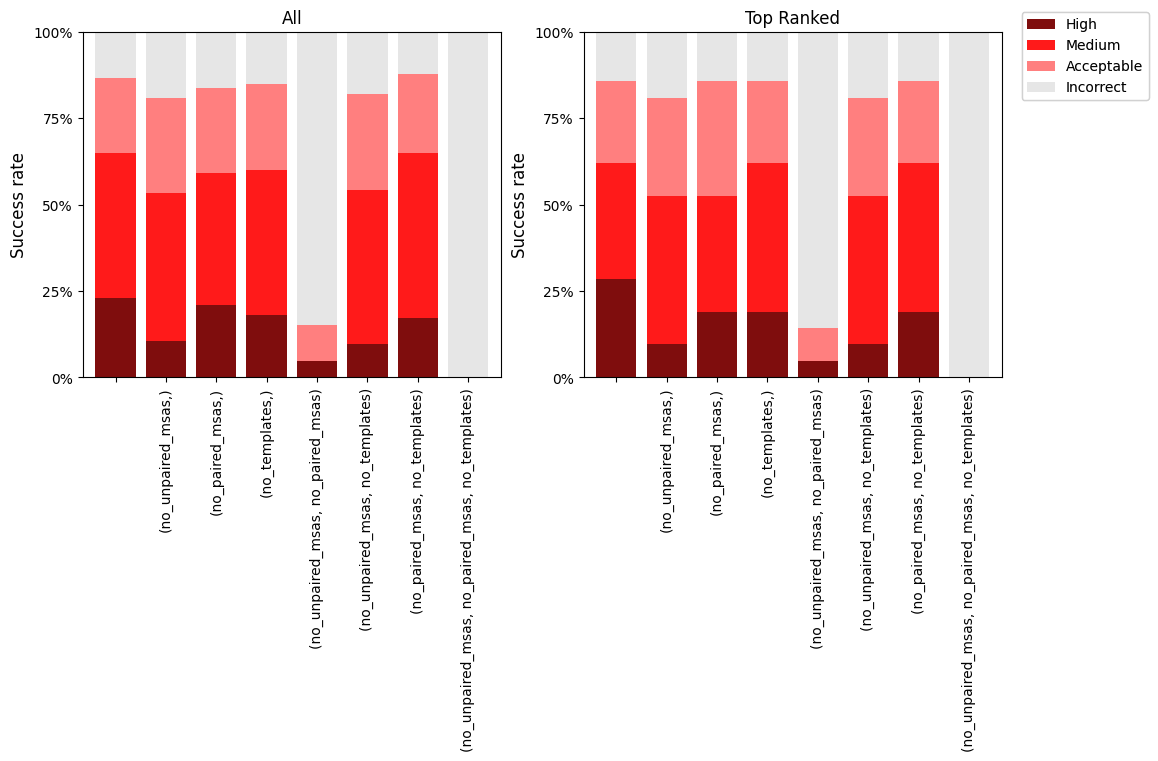

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(10, 7.5), constrained_layout=True)

for ax, title, data in zip(axes, ('All', 'Top Ranked'), (dockq_scores, dockq_scores.query('top_rank')), strict=True):
    ax.set_title(title)

    plot_capri_classification(data, ax=ax)

    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(handles, labels, bbox_to_anchor=(1.15, 1))

plt.show()